In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
WINDOW = 60
VAL_RATIO = 0.15
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [3]:
train_df = pd.read_csv("../data/Google_Stock_Train (2010-2022).csv", parse_dates=["Date"])
test_df = pd.read_csv("../data/Google_Stock_Test (2023).csv", parse_dates=["Date"])

In [4]:
train_df = train_df.sort_values("Date").reset_index(drop=True)
test_df = test_df.sort_values("Date").reset_index(drop=True)

In [5]:
train_close = train_df[["Close"]].values   # shape: (n, 1)
test_close = test_df[["Close"]].values

In [6]:
split_idx = int(len(train_close) * (1 - VAL_RATIO))
train_part = train_close[:split_idx]
val_part = train_close[split_idx - WINDOW:]  

In [7]:
scaler = MinMaxScaler()
scaler.fit(train_part)

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](1,)",[94.]
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](1,)",[10.91]
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](1,)",[83.09]
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](1,)",[-0.13]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,2781
"scale_ scale_: ndarray of shape (n_features,)Per feature relative scaling of the data. Equivalent to``(max - min) / (X.max(axis=0) - X.min(axis=0))``.. versionadded:: 0.17 *scale_* attribute.","ndarray[float64](1,)",[0.01]


In [8]:
train_scaled = scaler.transform(train_part)
val_scaled = scaler.transform(val_part)

In [9]:
test_input = np.vstack([train_close[-WINDOW:], test_close])
test_scaled = scaler.transform(test_input)

In [10]:
def make_windows(data, window):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i - window:i, 0])
        y.append(data[i, 0])
    X = np.array(X).reshape(-1, window, 1)   # RNN girdisi: (örnek, zaman adımı, özellik)
    y = np.array(y)
    return X, y

In [11]:
X_train, y_train = make_windows(train_scaled, WINDOW)
X_val, y_val = make_windows(val_scaled, WINDOW)
X_test, y_test = make_windows(test_scaled, WINDOW)

In [12]:
def report(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{name:12s} RMSE: {rmse:.3f}   MAE: {mae:.3f}")

In [13]:
y_test_real = test_close.ravel()

In [14]:
naive_pred = np.concatenate([[train_close[-1, 0]], test_close[:-1, 0]])
report("Naive", y_test_real, naive_pred)

Naive        RMSE: 2.243   MAE: 1.675


In [15]:
model = Sequential([
    SimpleRNN(50, input_shape=(WINDOW, 1)),
    Dense(1)
])

C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [16]:
model.compile(optimizer="adam", loss="mse")

In [17]:
early = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

In [18]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early],
    verbose=0
)

In [19]:
pred_scaled = model.predict(X_test)
pred = scaler.inverse_transform(pred_scaled).ravel() 

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step


In [20]:
report("SimpleRNN", y_test_real, pred)

SimpleRNN    RMSE: 2.392   MAE: 1.813


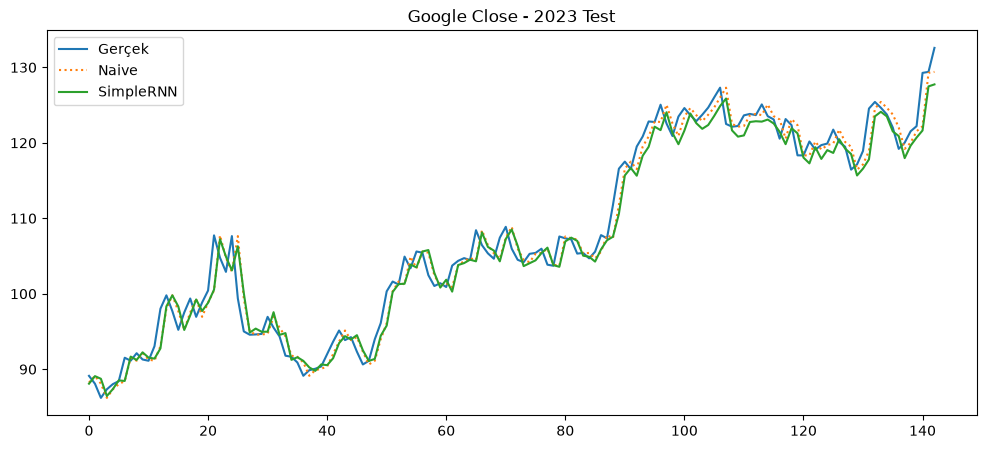

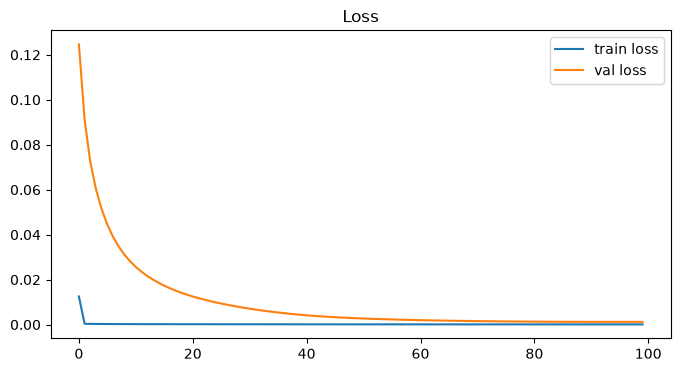

In [21]:
plt.figure(figsize=(12, 5))
plt.plot(y_test_real, label="Gerçek")
plt.plot(naive_pred, label="Naive", linestyle=":")
plt.plot(pred, label="SimpleRNN")
plt.title("Google Close - 2023 Test")
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.legend()
plt.title("Loss")
plt.show()

In [22]:
model.save("../model/google_stock_rnn.keras")